# NYC Yellow Taxi Trips — December 2025

An analysis of 4.3 million NYC yellow taxi trips during December 2025, exploring demand patterns, airport trips, tipping behavior, and traffic speed.

**Tools:** Python, pandas, DuckDB SQL, matplotlib, seaborn

## Data Loading and Exploration

In [1]:
import pandas as pd

In [2]:
df = pd.read_parquet("../data/raw/yellow_tripdata_2025-12.parquet")

In [3]:
df.shape


(4305006, 20)

In [4]:
df.columns

Index(['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime',
       'passenger_count', 'trip_distance', 'RatecodeID', 'store_and_fwd_flag',
       'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra',
       'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge',
       'total_amount', 'congestion_surcharge', 'Airport_fee',
       'cbd_congestion_fee'],
      dtype='str')

In [5]:
df.info(verbose=True, show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 4305006 entries, 0 to 4305005
Data columns (total 20 columns):
 #   Column                 Non-Null Count    Dtype         
---  ------                 --------------    -----         
 0   VendorID               4305006 non-null  int32         
 1   tpep_pickup_datetime   4305006 non-null  datetime64[us]
 2   tpep_dropoff_datetime  4305006 non-null  datetime64[us]
 3   passenger_count        3109524 non-null  float64       
 4   trip_distance          4305006 non-null  float64       
 5   RatecodeID             3109524 non-null  float64       
 6   store_and_fwd_flag     3109524 non-null  str           
 7   PULocationID           4305006 non-null  int32         
 8   DOLocationID           4305006 non-null  int32         
 9   payment_type           4305006 non-null  int64         
 10  fare_amount            4305006 non-null  float64       
 11  extra                  4305006 non-null  float64       
 12  mta_tax                4305006 non-null

In [6]:
df.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
0,1,2025-12-01 00:37:08,2025-12-01 00:51:10,1.0,2.40,1.0,N,140,48,1,14.2,4.25,0.5,4.00,0.00,1.0,23.95,2.5,0.00,0.75
1,2,2025-12-01 00:03:54,2025-12-01 00:19:18,1.0,8.37,1.0,N,138,262,1,33.1,6.00,0.5,7.77,6.94,1.0,59.56,2.5,1.75,0.00
2,2,2025-12-01 00:40:50,2025-12-01 01:06:54,1.0,15.26,1.0,N,132,255,1,57.6,1.00,0.5,12.02,0.00,1.0,73.87,0.0,1.75,0.00
3,1,2025-12-01 00:21:30,2025-12-01 00:49:35,2.0,18.40,2.0,N,132,79,1,70.0,5.00,0.5,10.00,0.00,1.0,86.50,2.5,1.75,0.75
4,2,2025-12-01 00:00:24,2025-12-01 00:03:34,1.0,0.52,1.0,N,239,238,1,5.8,1.00,0.5,1.62,0.00,1.0,12.42,2.5,0.00,0.00


In [7]:
df.describe()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
count,4.305006e+06,4305006,4305006,3.109524e+06,4.305006e+06,3.109524e+06,4.305006e+06,4.305006e+06,4.305006e+06,4.305006e+06,4.305006e+06,4.305006e+06,4.305006e+06,4.305006e+06,4.305006e+06,4.305006e+06,3.109524e+06,3.109524e+06,4.305006e+06
mean,1.879158e+00,2025-12-15 03:58:10.576246,2025-12-15 04:17:07.504495,1.313761e+00,6.941185e+00,4.795238e+00,1.617788e+02,1.611376e+02,8.732053e-01,2.221758e+01,1.072105e+00,4.816982e-01,2.828187e+00,5.119053e-01,9.492546e-01,3.087669e+01,2.166493e+00,1.475209e-01,5.272050e-01
min,1.000000e+00,2025-11-30 20:48:56,2025-11-30 20:57:48,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,-1.377100e+03,-7.500000e+00,-5.000000e-01,-9.650000e+01,-1.069300e+02,-1.000000e+00,-1.382850e+03,-2.500000e+00,-1.750000e+00,-7.500000e-01
25%,2.000000e+00,2025-12-08 01:59:12.500000,2025-12-08 02:15:24.500000,1.000000e+00,1.000000e+00,1.000000e+00,1.140000e+02,1.070000e+02,0.000000e+00,1.019000e+01,0.000000e+00,5.000000e-01,0.000000e+00,0.000000e+00,1.000000e+00,1.760000e+01,2.500000e+00,0.000000e+00,0.000000e+00
50%,2.000000e+00,2025-12-14 12:49:20,2025-12-14 13:04:10,1.000000e+00,1.810000e+00,1.000000e+00,1.610000e+02,1.620000e+02,1.000000e+00,1.694000e+01,0.000000e+00,5.000000e-01,2.000000e+00,0.000000e+00,1.000000e+00,2.442000e+01,2.500000e+00,0.000000e+00,7.500000e-01
75%,2.000000e+00,2025-12-21 03:50:19.500000,2025-12-21 04:04:26.500000,1.000000e+00,3.780000e+00,1.000000e+00,2.330000e+02,2.340000e+02,1.000000e+00,2.820000e+01,2.500000e+00,5.000000e-01,4.000000e+00,0.000000e+00,1.000000e+00,3.653000e+01,2.500000e+00,0.000000e+00,7.500000e-01
max,7.000000e+00,2025-12-31 23:59:59,2026-01-05 13:00:34,9.000000e+00,3.225762e+05,9.900000e+01,2.650000e+02,2.650000e+02,4.000000e+00,2.157600e+03,1.500000e+01,9.600000e+01,8.000000e+02,1.069300e+02,1.000000e+00,2.162350e+03,2.500000e+00,6.750000e+00,7.500000e-01
std,7.262168e-01,NaN,NaN,7.424818e-01,7.184367e+02,1.863672e+01,6.669929e+01,7.068688e+01,7.200375e-01,1.985225e+01,1.756524e+00,1.277528e-01,4.107690e+00,2.151309e+00,2.655103e-01,2.378989e+01,9.374290e-01,5.238357e-01,3.550992e-01


In [8]:
df.DOLocationID.nunique()

261

In [9]:
df.store_and_fwd_flag.describe()

count     3109524
unique          2
top             N
freq      3104510
Name: store_and_fwd_flag, dtype: object

In [10]:
df.isna().sum()


VendorID                       0
tpep_pickup_datetime           0
tpep_dropoff_datetime          0
passenger_count          1195482
trip_distance                  0
RatecodeID               1195482
store_and_fwd_flag       1195482
PULocationID                   0
DOLocationID                   0
payment_type                   0
fare_amount                    0
extra                          0
mta_tax                        0
tip_amount                     0
tolls_amount                   0
improvement_surcharge          0
total_amount                   0
congestion_surcharge     1195482
Airport_fee              1195482
cbd_congestion_fee             0
dtype: int64

In [11]:
df[df["passenger_count"].isna()].head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
3109524,2,2025-12-01 00:10:03,2025-12-01 00:22:17,NaN,2.55,NaN,NaN,75,42,0,12.45,0.0,0.5,0.0,0.0,1.0,13.95,NaN,NaN,0.00
3109525,2,2025-12-01 00:15:55,2025-12-01 00:22:06,NaN,1.11,NaN,NaN,140,263,0,6.82,0.0,0.5,0.0,0.0,1.0,10.82,NaN,NaN,0.00
3109526,2,2025-12-01 00:53:26,2025-12-01 01:05:05,NaN,2.97,NaN,NaN,140,75,0,12.73,0.0,0.5,0.0,0.0,1.0,16.73,NaN,NaN,0.00
3109527,2,2025-12-01 00:50:32,2025-12-01 01:06:58,NaN,9.11,NaN,NaN,191,216,0,23.91,0.0,0.5,0.0,0.0,1.0,25.41,NaN,NaN,0.00
3109528,2,2025-12-01 00:03:03,2025-12-01 00:16:22,NaN,2.08,NaN,NaN,230,137,0,14.91,0.0,0.5,0.0,0.0,1.0,20.66,NaN,NaN,0.75


In [12]:
df["VendorID"].value_counts()

VendorID
2    3417640
1     825421
7      57416
6       4529
Name: count, dtype: int64

In [13]:
df["payment_type"].value_counts()

payment_type
1    2618772
0    1195482
2     401019
4      69145
3      20588
Name: count, dtype: int64

In [14]:
df["tpep_pickup_datetime"].min()

Timestamp('2025-11-30 20:48:56')

In [15]:
df["tpep_pickup_datetime"].max()

Timestamp('2025-12-31 23:59:59')

## Tracing Nulls to Flex Fare

In [16]:
df.loc[df["payment_type"] == 0, "passenger_count"].isna().value_counts()

passenger_count
True    1195482
Name: count, dtype: int64

In [17]:
null_cols = ["passenger_count", "RatecodeID", "store_and_fwd_flag",
             "congestion_surcharge", "Airport_fee"]

all_null = df[null_cols].isna().all(axis=1)
print(all_null.sum(), df[null_cols].isna().any(axis=1).sum())
pd.crosstab(all_null, df["payment_type"])

1195482 1195482


payment_type,0,1,2,3,4
row_0,,,,,
False,0,2618772,401019,20588,69145
True,1195482,0,0,0,0


In [18]:
pd.crosstab(all_null, df["VendorID"])

VendorID,1,2,6,7
row_0,,,,
False,677840,2374268,0,57416
True,147581,1043372,4529,0


In [19]:
df["payment_type"].value_counts().sort_index()

payment_type
0    1195482
1    2618772
2     401019
3      20588
4      69145
Name: count, dtype: int64

In [20]:
print(df.describe().T.to_string())

                           count                        mean                  min                         25%                  50%                         75%                  max         std
VendorID               4305006.0                    1.879158                  1.0                         2.0                  2.0                         2.0                  7.0    0.726217
tpep_pickup_datetime     4305006  2025-12-15 03:58:10.576246  2025-11-30 20:48:56  2025-12-08 01:59:12.500000  2025-12-14 12:49:20  2025-12-21 03:50:19.500000  2025-12-31 23:59:59         NaN
tpep_dropoff_datetime    4305006  2025-12-15 04:17:07.504495  2025-11-30 20:57:48  2025-12-08 02:15:24.500000  2025-12-14 13:04:10  2025-12-21 04:04:26.500000  2026-01-05 13:00:34         NaN
passenger_count        3109524.0                    1.313761                  0.0                         1.0                  1.0                         1.0                  9.0    0.742482
trip_distance          4305006.0        

## Quality Checks

In [21]:
pickup = df["tpep_pickup_datetime"]
dropoff = df["tpep_dropoff_datetime"]
duration_min = (dropoff - pickup).dt.total_seconds() / 60

checks = {
    "pickup outside December": ~((pickup >= "2025-12-01") & (pickup < "2026-01-01")),
    "dropoff before pickup": dropoff < pickup,
    "duration <= 0 min": duration_min <= 0,
    "duration > 3 hours": duration_min > 180,
    "distance == 0": df["trip_distance"] == 0,
    "distance > 100 miles": df["trip_distance"] > 100,
    "fare <= 0": df["fare_amount"] <= 0,
    "fare > 500": df["fare_amount"] > 500,
    "total_amount <= 0": df["total_amount"] <= 0,
    "tip < 0": df["tip_amount"] < 0,
    "passenger_count == 0": df["passenger_count"] == 0,
    "RatecodeID == 99": df["RatecodeID"] == 99,
}

counts = pd.Series({name: mask.sum() for name, mask in checks.items()})
print(pd.DataFrame({"rows": counts, "pct": (counts / len(df) * 100).round(3)}))

                           rows    pct
pickup outside December       9  0.000
dropoff before pickup         2  0.000
duration <= 0 min         58021  1.348
duration > 3 hours         2160  0.050
distance == 0            152656  3.546
distance > 100 miles        197  0.005
fare <= 0                 50716  1.178
fare > 500                   62  0.001
total_amount <= 0         49490  1.150
tip < 0                      78  0.002
passenger_count == 0      18827  0.437
RatecodeID == 99         117021  2.718


## Drop Rules

In [22]:
drop_rules = ["pickup outside December", "duration <= 0 min", "duration > 3 hours",
              "fare <= 0", "total_amount <= 0", "distance > 100 miles", "fare > 500"]

keep = pd.Series(True, index=df.index)
log = []
for name in drop_rules:
    mask = checks[name]
    log.append({"rule": name,
                "flagged": mask.sum(),
                "newly_removed": (mask & keep).sum()})
    keep &= ~mask

print(f"Would keep {keep.sum():,} of {len(df):,} rows ({keep.mean():.2%})")
pd.DataFrame(log)

Would keep 4,193,842 of 4,305,006 rows (97.42%)


,rule,flagged,newly_removed
0,pickup outside December,9,9
1,duration <= 0 min,58021,58021
2,duration > 3 hours,2160,2160
3,fare <= 0,50716,50662
4,total_amount <= 0,49490,96
5,distance > 100 miles,197,174
6,fare > 500,62,42


## Identifying Suspicious Rows

In [23]:
suspicious = ["duration <= 0 min", "fare <= 0", "total_amount <= 0", "distance == 0"]

by_payment = pd.DataFrame({name: df.loc[checks[name], "payment_type"].value_counts()
                           for name in suspicious})
by_payment["all rows"] = df["payment_type"].value_counts()
by_payment.fillna(0).astype(int)

,duration <= 0 min,fare <= 0,total_amount <= 0,distance == 0,all rows
payment_type,,,,,
0,113,507,138,109607,1195482
1,49452,313,304,24578,2618772
2,7612,12202,11407,9799,401019
3,545,5804,5780,3862,20588
4,299,31890,31861,4810,69145


## Zero Distance Trips

In [24]:
zero_dist = checks["distance == 0"]
same_zone = df.loc[zero_dist, "PULocationID"] == df.loc[zero_dist, "DOLocationID"]
print(f"Zero-distance trips with same pickup/dropoff zone: {same_zone.mean():.1%}")
df.loc[zero_dist, "fare_amount"].describe()

Zero-distance trips with same pickup/dropoff zone: 24.4%


count    152656.000000
mean         30.450512
std          31.269959
min        -980.000000
25%          14.260000
50%          24.380000
75%          39.320000
max         999.000000
Name: fare_amount, dtype: float64

## Final Drop Rules and Flagging

In [25]:
final_drop_rules = ["pickup outside December", "duration > 3 hours", "fare <= 0",
              "distance > 100 miles", "fare > 500"]
drop_mask = pd.concat([checks[r] for r in final_drop_rules], axis=1).any(axis=1)

clean = df.loc[~drop_mask].copy()
clean["duration_min"] = (clean["tpep_dropoff_datetime"] - clean["tpep_pickup_datetime"]).dt.total_seconds() / 60
clean["is_flex_fare"] = clean["payment_type"] == 0
clean["bad_duration"] = clean["duration_min"] <= 0
clean["zero_distance"] = clean["trip_distance"] == 0

print(f"Dropped {drop_mask.sum():,} rows; kept {len(clean):,} ({len(clean) / len(df):.2%})")
clean[["is_flex_fare", "bad_duration", "zero_distance"]].sum()

Dropped 53,084 rows; kept 4,251,922 (98.77%)


is_flex_fare     1194787
bad_duration       57984
zero_distance     148293
dtype: int64

### Cleaning decisions

- **Zero-distance trips:** Median fare of about $24, missing distance reading. Flag rather than delete them.
- **Non-positive fares:** These records are mostly associated with payment types 3 (No charge) and 4 (Dispute), not revenue trips.
- **Cleaning thresholds:** The 3-hour, 100-mile, and $500 thresholds are judgment calls.

98.8% of trips were retained.

In [26]:
from pathlib import Path

out_dir = Path("../data/processed")
out_dir.mkdir(parents=True, exist_ok=True)
clean.to_parquet(out_dir / "yellow_2025-12_clean.parquet", index=False)

## SQL Analysis

## DuckDB Setup and Views

In [27]:
import duckdb

con = duckdb.connect() 
con.execute("""
    CREATE VIEW trips AS
    SELECT * FROM read_parquet('../data/processed/yellow_2025-12_clean.parquet')
""")
con.sql("SELECT COUNT(*) AS n FROM trips").df()

,n
0,4251922


In [28]:
con.execute("""
    CREATE VIEW zones AS
    SELECT * FROM read_csv_auto('../data/raw/taxi_zone_lookup.csv')
""")
con.sql("SELECT * FROM zones LIMIT 5").df()

,LocationID,Borough,Zone,service_zone
0,1,EWR,Newark Airport,EWR
1,2,Queens,Jamaica Bay,Boro Zone
2,3,Bronx,Allerton/Pelham Gardens,Boro Zone
3,4,Manhattan,Alphabet City,Yellow Zone
4,5,Staten Island,Arden Heights,Boro Zone


### Top 10 pickup zones

In [29]:
con.sql("""
    SELECT t.PULocationID, z.Borough, z.Zone,
           COUNT(*) AS trips,
           ROUND(AVG(t.fare_amount), 2) AS avg_fare
    FROM trips t
    JOIN zones z ON t.PULocationID = z.LocationID
    GROUP BY t.PULocationID, z.Borough, z.Zone
    ORDER BY trips DESC
    LIMIT 10
""").df()

,PULocationID,Borough,Zone,trips,avg_fare
0,237,Manhattan,Upper East Side South,193985,14.99
1,236,Manhattan,Upper East Side North,175974,15.34
2,161,Manhattan,Midtown Center,159925,20.79
3,132,Queens,JFK Airport,156576,63.06
4,186,Manhattan,Penn Station/Madison Sq West,133261,19.65
5,142,Manhattan,Lincoln Square East,132506,16.71
6,162,Manhattan,Midtown East,129255,18.89
7,230,Manhattan,Times Sq/Theatre District,119572,23.87
8,239,Manhattan,Upper West Side South,112975,16.83
9,234,Manhattan,Union Sq,111702,18.92


### Trips by hour of day

In [30]:
con.sql("""
    SELECT hour(tpep_pickup_datetime) AS hour, COUNT(*) AS trips
    FROM trips
    GROUP BY hour
    ORDER BY hour
""").df()

,hour,trips
0,0,137829
1,1,86311
2,2,55048
3,3,36759
4,4,31786
5,5,34633
6,6,68523
7,7,121023
8,8,160847
9,9,176164


### Trips by day of week

In [31]:
con.sql("""
    SELECT isodow(tpep_pickup_datetime) AS dow,
           dayname(tpep_pickup_datetime) AS day,
           COUNT(*) AS trips
    FROM trips
    GROUP BY dow, day
    ORDER BY dow
""").df()

,dow,day,trips
0,1,Monday,621973
1,2,Tuesday,674303
2,3,Wednesday,679842
3,4,Thursday,580095
4,5,Friday,601432
5,6,Saturday,584364
6,7,Sunday,509913


### Trips by day x hour

In [32]:
demand = con.sql("""
    SELECT isodow(tpep_pickup_datetime) AS dow,
           hour(tpep_pickup_datetime) AS hour,
           COUNT(*) AS trips
    FROM trips
    GROUP BY dow, hour
    ORDER BY dow, hour
""").df()

demand.pivot(index="dow", columns="hour", values="trips")

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
dow,,,,,,,,,,,,,,,,,,,,,
1,11120,6117,3364,2476,3466,5984,12530,22672,29143,30311,...,37706,40706,40715,44048,43660,36408,35112,36406,28702,19364
2,12115,5631,3172,2000,2784,5231,12313,23034,30707,32763,...,40285,42908,43321,46414,47327,40125,39641,42272,36848,25777
3,15495,7329,4063,2647,3196,5169,11501,21971,29135,30248,...,37874,40664,41513,45191,47371,44864,42082,44576,40812,31505
4,15691,7809,4261,2765,3008,4566,9870,18887,24646,24307,...,30379,32772,32921,37445,41217,37800,36972,39549,37929,33268
5,22561,12673,7377,4314,3905,5130,10329,18694,24273,24368,...,33121,34996,36550,39204,42729,38845,32709,32304,34788,34715
6,29978,22629,15852,10466,6684,3780,5580,7947,12043,17935,...,31245,33508,34907,36519,38120,36644,31463,30937,34690,34772
7,30869,24123,16959,12091,8743,4773,6400,7818,10900,16232,...,30321,31689,32731,32214,30506,27652,24650,23221,18968,13802


### Top 10 zone pairs, excluding saem-zone

In [33]:
con.sql("""
    SELECT t.PULocationID, t.DOLocationID,
           pz.Zone AS pickup, dz.Zone AS dropoff,
           COUNT(*) AS trips,
           ROUND(AVG(t.fare_amount), 2) AS avg_fare
    FROM trips t
    JOIN zones pz ON t.PULocationID = pz.LocationID
    JOIN zones dz ON t.DOLocationID = dz.LocationID
    WHERE t.PULocationID <> t.DOLocationID
    GROUP BY t.PULocationID, t.DOLocationID, pz.Zone, dz.Zone
    ORDER BY trips DESC
    LIMIT 10
""").df()

,PULocationID,DOLocationID,pickup,dropoff,trips,avg_fare
0,237,236,Upper East Side South,Upper East Side North,29127,9.27
1,236,237,Upper East Side North,Upper East Side South,25941,10.19
2,237,161,Upper East Side South,Midtown Center,11319,13.16
3,161,237,Midtown Center,Upper East Side South,10922,12.32
4,142,239,Lincoln Square East,Upper West Side South,10505,8.47
5,237,162,Upper East Side South,Midtown East,10026,11.68
6,239,238,Upper West Side South,Upper West Side North,9982,7.68
7,239,142,Upper West Side South,Lincoln Square East,9819,8.54
8,141,236,Lenox Hill West,Upper East Side North,9373,9.55
9,186,230,Penn Station/Madison Sq West,Times Sq/Theatre District,9107,18.00


### Flex Fare vs. other

In [34]:
con.sql("""
    SELECT is_flex_fare,
           COUNT(*) AS trips,
           ROUND(AVG(fare_amount), 2) AS avg_fare,
           ROUND(AVG(trip_distance) FILTER (WHERE NOT zero_distance), 2) AS avg_miles,
           ROUND(AVG(duration_min) FILTER (WHERE NOT bad_duration), 1) AS avg_minutes
    FROM trips
    GROUP BY is_flex_fare
""").df()

,is_flex_fare,trips,avg_fare,avg_miles,avg_minutes
0,True,1194787,27.68,3.71,19.0
1,False,3057135,20.83,3.44,18.7


### Daily trips

In [35]:
con.sql("""
    SELECT CAST(tpep_pickup_datetime AS DATE) AS date,
           dayname(tpep_pickup_datetime) AS day,
           COUNT(*) AS trips
    FROM trips
    GROUP BY date, day
    ORDER BY date
""").df()

,date,day,trips
0,2025-12-01,Monday,123652
1,2025-12-02,Tuesday,144801
2,2025-12-03,Wednesday,148734
3,2025-12-04,Thursday,169243
4,2025-12-05,Friday,168362
5,2025-12-06,Saturday,166478
6,2025-12-07,Sunday,139396
7,2025-12-08,Monday,141283
8,2025-12-09,Tuesday,157724
9,2025-12-10,Wednesday,163931


### Avg trips per day

In [36]:
con.sql("""
    WITH daily AS (
        SELECT CAST(tpep_pickup_datetime AS DATE) AS date, COUNT(*) AS trips
        FROM trips
        GROUP BY date
    )
    SELECT isodow(date) AS dow,
           dayname(date) AS day,
           COUNT(*) AS days_in_data,
           ROUND(AVG(trips)) AS avg_trips_per_day
    FROM daily
    GROUP BY dow, day
    ORDER BY dow
""").df()

,dow,day,days_in_data,avg_trips_per_day
0,1,Monday,5,124395.0
1,2,Tuesday,5,134861.0
2,3,Wednesday,5,135968.0
3,4,Thursday,4,145024.0
4,5,Friday,4,150358.0
5,6,Saturday,4,146091.0
6,7,Sunday,4,127478.0


### Flex Fare vs. other, excluding airport 

In [37]:
con.sql("""
    SELECT is_flex_fare,
           COUNT(*) AS trips,
           ROUND(AVG(fare_amount), 2) AS avg_fare,
           ROUND(AVG(trip_distance), 2) AS avg_miles,
           ROUND(SUM(fare_amount) / SUM(trip_distance), 2) AS fare_per_mile
    FROM trips
    WHERE NOT zero_distance
      AND PULocationID NOT IN (1, 132, 138)
      AND DOLocationID NOT IN (1, 132, 138)
    GROUP BY is_flex_fare
""").df()

,is_flex_fare,trips,avg_fare,avg_miles,fare_per_mile
0,False,2699498,16.24,2.31,7.04
1,True,1071787,26.99,3.60,7.50


### Avg trips per weekday Dec 1-19

In [38]:
con.sql("""
    WITH daily AS (
        SELECT CAST(tpep_pickup_datetime AS DATE) AS date, COUNT(*) AS trips
        FROM trips
        WHERE CAST(tpep_pickup_datetime AS DATE) BETWEEN DATE '2025-12-01' AND DATE '2025-12-19'
        GROUP BY date
    )
    SELECT isodow(date) AS dow, dayname(date) AS day,
           COUNT(*) AS days_in_data,
           ROUND(AVG(trips)) AS avg_trips_per_day
    FROM daily
    GROUP BY dow, day
    ORDER BY dow
""").df()

,dow,day,days_in_data,avg_trips_per_day
0,1,Monday,3,137981.0
1,2,Tuesday,3,153090.0
2,3,Wednesday,3,156915.0
3,4,Thursday,3,171061.0
4,5,Friday,3,172982.0
5,6,Saturday,2,172570.0
6,7,Sunday,2,148851.0


### Airport vs. other

In [39]:
con.sql("""
    SELECT CASE WHEN PULocationID = 132 OR DOLocationID = 132 THEN 'JFK'
                WHEN PULocationID = 138 OR DOLocationID = 138 THEN 'LaGuardia'
                WHEN PULocationID = 1   OR DOLocationID = 1   THEN 'Newark'
                ELSE 'Non-airport' END AS trip_group,
           COUNT(*) AS trips,
           ROUND(AVG(fare_amount), 2) AS avg_fare,
           ROUND(AVG(trip_distance), 2) AS avg_miles,
           ROUND(AVG(duration_min), 1) AS avg_minutes,
           ROUND(100 * SUM(tip_amount) FILTER (WHERE payment_type = 1)
                 / SUM(fare_amount) FILTER (WHERE payment_type = 1), 1) AS card_tip_pct
    FROM trips
    WHERE NOT zero_distance AND NOT bad_duration
    GROUP BY trip_group
    ORDER BY trips DESC
""").df()

,trip_group,trips,avg_fare,avg_miles,avg_minutes,card_tip_pct
0,Non-airport,3718843,19.36,2.69,17.0,21.5
1,JFK,180453,64.49,15.44,46.6,18.9
2,LaGuardia,139793,47.13,9.63,33.6,23.7
3,Newark,8577,98.59,16.83,42.6,18.5


### Tip % by hour

In [40]:
con.sql("""
    SELECT hour(tpep_pickup_datetime) AS hour,
           COUNT(*) AS card_trips,
           ROUND(100 * SUM(tip_amount) / SUM(fare_amount), 1) AS tip_pct
    FROM trips
    WHERE payment_type = 1
    GROUP BY hour
    ORDER BY hour
""").df()

,hour,card_trips,tip_pct
0,0,66935,21.8
1,1,39667,22.0
2,2,24652,22.0
3,3,15207,20.8
4,4,11597,17.4
5,5,14271,14.3
6,6,31669,14.9
7,7,64746,17.7
8,8,92574,19.1
9,9,111336,19.8


### Avg speed per hour, weekdays Dec 1-19

In [41]:
speed = con.sql("""
    SELECT hour(tpep_pickup_datetime) AS hour,
           COUNT(*) AS trips,
           ROUND(SUM(trip_distance) / SUM(duration_min) * 60, 1) AS avg_mph
    FROM trips
    WHERE NOT zero_distance AND NOT bad_duration
      AND duration_min >= 1
      AND trip_distance / (duration_min / 60) < 80
      AND PULocationID NOT IN (1, 132, 138)
      AND DOLocationID NOT IN (1, 132, 138)
      AND isodow(tpep_pickup_datetime) BETWEEN 1 AND 5
      AND CAST(tpep_pickup_datetime AS DATE) BETWEEN DATE '2025-12-01' AND DATE '2025-12-19'
    GROUP BY hour
    ORDER BY hour
""").df()
speed

,hour,trips,avg_mph
0,0,49879,14.2
1,1,25166,16.1
2,2,14274,17.2
3,3,8685,17.9
4,4,9022,17.7
5,5,15833,15.5
6,6,38639,13.4
7,7,79008,11.0
8,8,103262,9.5
9,9,100027,8.7


## Visualizations and Findings

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from pathlib import Path

fig_dir = Path("../figures")
fig_dir.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")

### Demand by day and hour

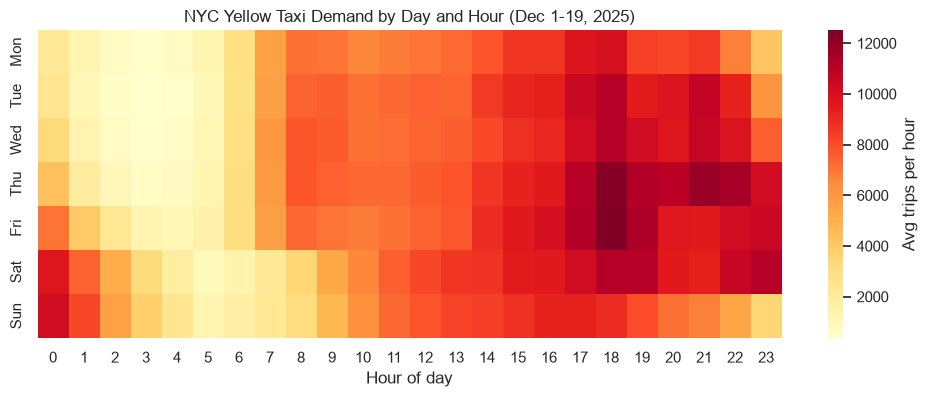

In [43]:
heat = con.sql("""
    WITH hourly AS (
        SELECT CAST(tpep_pickup_datetime AS DATE) AS date,
               isodow(tpep_pickup_datetime) AS dow,
               hour(tpep_pickup_datetime) AS hour,
               COUNT(*) AS trips
        FROM trips
        WHERE CAST(tpep_pickup_datetime AS DATE) BETWEEN DATE '2025-12-01' AND DATE '2025-12-19'
        GROUP BY date, dow, hour
    )
    SELECT dow, hour, AVG(trips) AS avg_trips
    FROM hourly
    GROUP BY dow, hour
""").df()

pivot = heat.pivot(index="dow", columns="hour", values="avg_trips")
pivot.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

fig, ax = plt.subplots(figsize=(12, 4))
sns.heatmap(pivot, cmap="YlOrRd", ax=ax, cbar_kws={"label": "Avg trips per hour"})
ax.set_title("NYC Yellow Taxi Demand by Day and Hour (Dec 1-19, 2025)")
ax.set_xlabel("Hour of day")
ax.set_ylabel("")
plt.savefig(fig_dir / "demand_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

### Trips by day

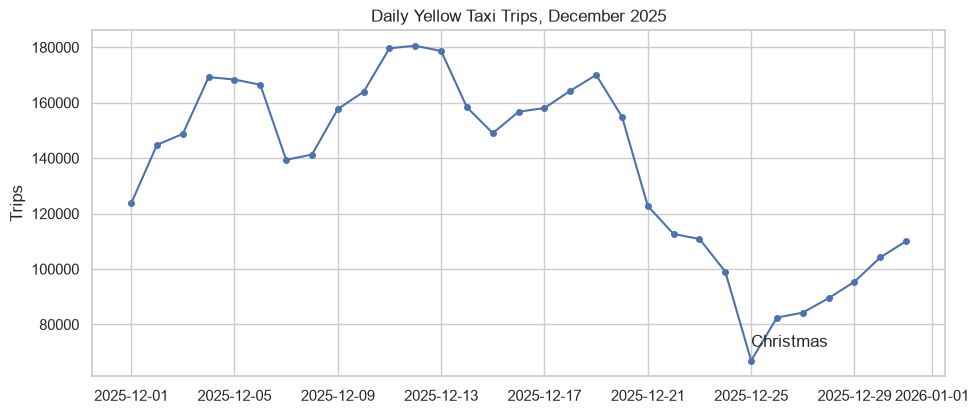

In [44]:
daily = con.sql("""
    SELECT CAST(tpep_pickup_datetime AS DATE) AS date, COUNT(*) AS trips
    FROM trips
    GROUP BY date
    ORDER BY date
""").df()
daily["date"] = pd.to_datetime(daily["date"])

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(daily["date"], daily["trips"], marker="o", markersize=4)
xmas = daily[daily["date"] == "2025-12-25"].iloc[0]
ax.annotate("Christmas", xy=(xmas["date"], xmas["trips"]),
            xytext=(xmas["date"], xmas["trips"] + 5000))
ax.set_title("Daily Yellow Taxi Trips, December 2025")
ax.set_ylabel("Trips")
ax.set_xlabel("")
plt.savefig(fig_dir / "daily_trips.png", dpi=150, bbox_inches="tight")
plt.show()

### Shares of airport trips vs. fares

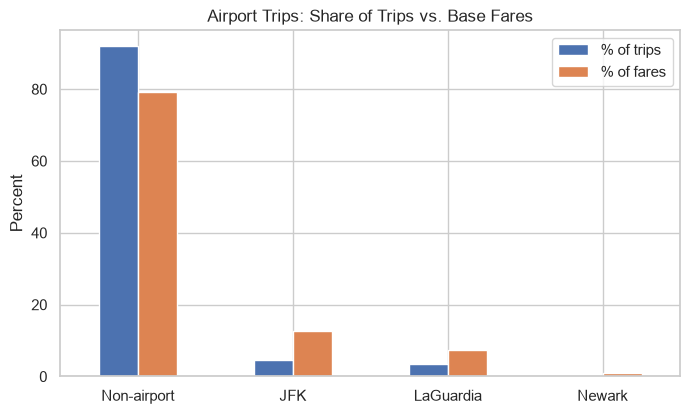

In [45]:
groups = con.sql("""
    SELECT CASE WHEN PULocationID = 132 OR DOLocationID = 132 THEN 'JFK'
                WHEN PULocationID = 138 OR DOLocationID = 138 THEN 'LaGuardia'
                WHEN PULocationID = 1   OR DOLocationID = 1   THEN 'Newark'
                ELSE 'Non-airport' END AS trip_group,
           COUNT(*) AS trips,
           SUM(fare_amount) AS fares
    FROM trips
    WHERE NOT zero_distance AND NOT bad_duration
    GROUP BY trip_group
""").df().set_index("trip_group").loc[["Non-airport", "JFK", "LaGuardia", "Newark"]]

groups["% of trips"] = 100 * groups["trips"] / groups["trips"].sum()
groups["% of fares"] = 100 * groups["fares"] / groups["fares"].sum()

ax = groups[["% of trips", "% of fares"]].plot(kind="bar", figsize=(8, 4.5), rot=0)
ax.set_title("Airport Trips: Share of Trips vs. Base Fares")
ax.set_ylabel("Percent")
ax.set_xlabel("")
plt.savefig(fig_dir / "airport_share.png", dpi=150, bbox_inches="tight")
plt.show()

In [46]:
groups[["% of trips", "% of fares"]].round(1)

,% of trips,% of fares
trip_group,,
Non-airport,91.9,79.1
JFK,4.5,12.8
LaGuardia,3.5,7.2
Newark,0.2,0.9


### Tip % by hour

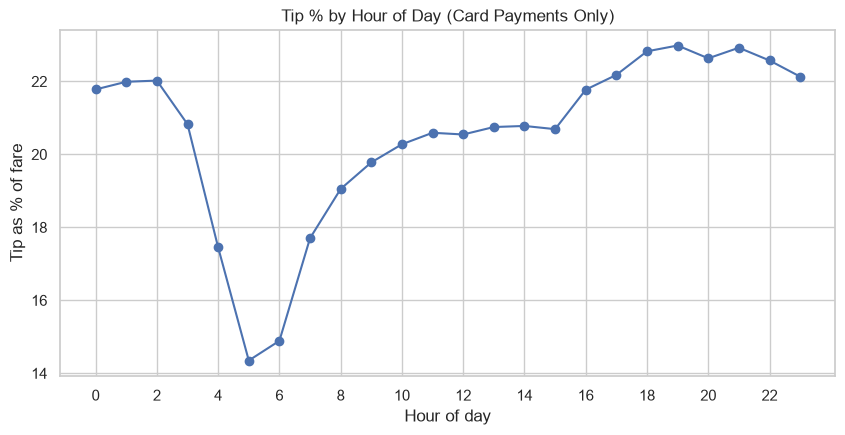

In [47]:
tips = con.sql("""
    SELECT hour(tpep_pickup_datetime) AS hour,
           100 * SUM(tip_amount) / SUM(fare_amount) AS tip_pct
    FROM trips
    WHERE payment_type = 1
    GROUP BY hour
    ORDER BY hour
""").df()

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(tips["hour"], tips["tip_pct"], marker="o")
ax.set_title("Tip % by Hour of Day (Card Payments Only)")
ax.set_xlabel("Hour of day")
ax.set_ylabel("Tip as % of fare")
ax.set_xticks(range(0, 24, 2))
plt.savefig(fig_dir / "tip_by_hour.png", dpi=150, bbox_inches="tight")
plt.show()

### Speed by hour

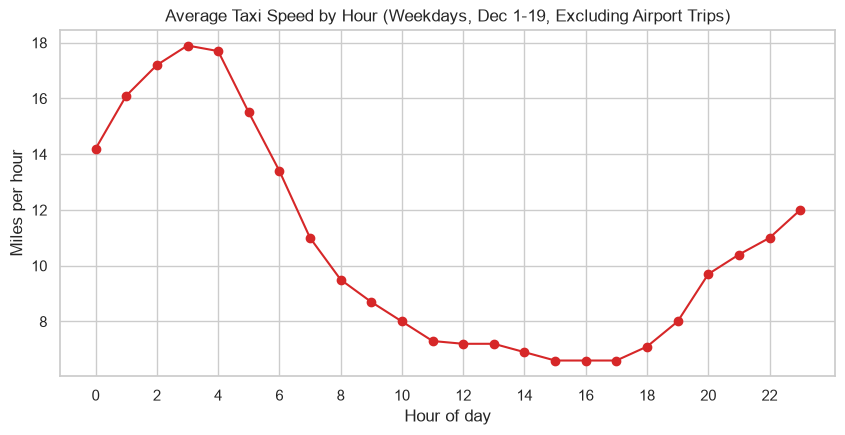

In [52]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(speed["hour"], speed["avg_mph"], marker="o", color="tab:red")
ax.set_title("Average Taxi Speed by Hour (Weekdays, Dec 1-19, Excluding Airport Trips)")
ax.set_xlabel("Hour of day")
ax.set_ylabel("Miles per hour")
ax.set_xticks(range(0, 24, 2))
plt.savefig(fig_dir / "speed_by_hour.png", dpi=150, bbox_inches="tight")
plt.show()